# Lidar and photogrammetry in a forest: ČÚZK point clouds and models

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/lidar_canopy_en.ipynb)

**OpenSkyLab · notebook for the visual** [LiDAR vs photogrammetry under canopy](https://openskylab.space/edu_viz_lidar_canopy.html) · [česká verze](lidar_canopy_cs.ipynb)

The visual shows why a laser pulse finds the ground even under tree crowns while photogrammetry sees only the surface. Here you check it on real ČÚZK data from the Roztoky forest near Suchdol: ground and surface points from airborne laser scanning and a surface from image matching of aerial photographs.

**Goal:** load and inspect LAZ point clouds, find out which return the ground points come from in the forest and in the open, compute the canopy height model CHM = DSM − DTM from lidar and from photogrammetry, compare them in a profile, find tree tops and explain the differences.

**Data:** ČÚZK: DMR 5G (ground points from airborne laser scanning, LAZ) and DMP 1G (surface points, LAZ) for the map sheet Kralupy nad Vltavou 7-7, DMR 5G, DMP 1G and DMP OK (image matching) rasters from the ČÚZK image service; all in S-JTSK (EPSG:5514), heights in Bpv. ČÚZK data are open (CC BY 4.0).

**Tasks:** six. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 50 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and point clouds

In [1]:
%pip install -q "laspy[lazrs]" rasterio

Note: you may need to restart the kernel to use updated packages.


window 1.0 × 0.7 km, scanned around 09 Oct 2010
                         points  points per m²
DMR 5G: ground            62555          0.089
DMP 1G: ground            12834          0.018
DMP 1G: high vegetation  139724          0.200
DMP 1G: buildings         12713          0.018


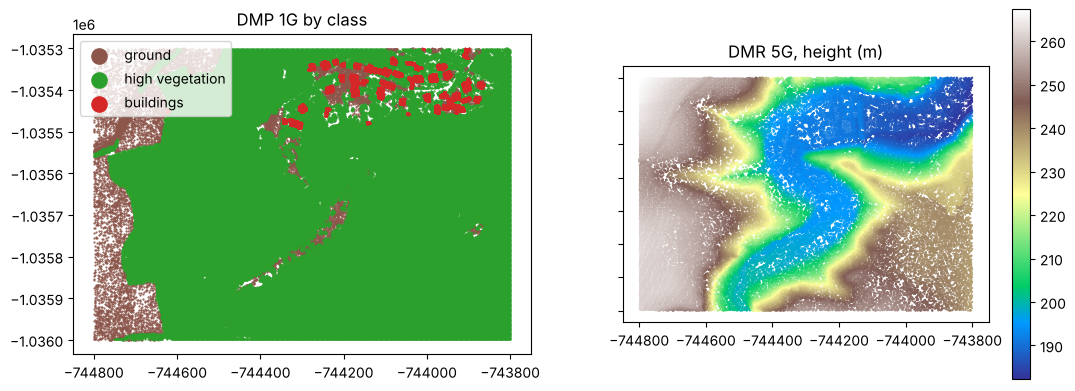

In [2]:
import io, time, zipfile, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import laspy, rasterio
from scipy import ndimage as ndi

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

SHEET = "KRAV77"              # ◀ parameter: SM5 map sheet (sheet names are listed in the ČÚZK Atom service)
X0, Y0, X1, Y1 = -744800, -1036000, -743800, -1035300   # ◀ parameter: window in S-JTSK (m), the Roztoky forest and the Tiché údolí valley

def laz(product, sheet, tries=4):
    for i in range(tries):
        try:
            r = requests.get(f"https://openzu.cuzk.gov.cz/opendata/{product}/epsg-5514/{sheet}.zip", timeout=180); r.raise_for_status(); break
        except requests.RequestException as e:
            print(product, type(e).__name__, "– retrying"); time.sleep(5 * (i + 1))
    z = zipfile.ZipFile(io.BytesIO(r.content))
    las = laspy.read(io.BytesIO(z.read(z.namelist()[0])))
    m = (las.x >= X0) & (las.x < X1) & (las.y >= Y0) & (las.y < Y1)
    return las.points[m]

ground = laz("DMR5G", SHEET)          # ground points (key points of the terrain model)
surface = laz("DMP1G", SHEET)         # surface points: 2 ground, 5 high vegetation, 6 buildings
area = (X1 - X0) * (Y1 - Y0)
gps = np.median(np.asarray(ground.gps_time)) + 1e9          # "adjusted GPS time" = seconds since 6 Jan 1980 minus 10⁹
print(f"window {(X1 - X0) / 1000:.1f} × {(Y1 - Y0) / 1000:.1f} km, scanned around {pd.Timestamp('1980-01-06') + pd.Timedelta(seconds=gps):%d %b %Y}")
CLS = {2: "ground", 5: "high vegetation", 6: "buildings"}
tab = pd.DataFrame({"points": [len(ground)] + [int((surface.classification == c).sum()) for c in CLS]},
                   index=["DMR 5G: ground"] + [f"DMP 1G: {n}" for n in CLS.values()])
tab["points per m²"] = tab["points"] / area
print(tab.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for c, col in zip(CLS, ["tab:brown", "tab:green", "tab:red"]):
    s = surface.classification == c
    ax[0].scatter(surface.x[s], surface.y[s], s=0.3, c=col, label=CLS[c])
ax[0].legend(markerscale=20); ax[0].set_title("DMP 1G by class"); ax[0].set_aspect("equal")
sc = ax[1].scatter(ground.x, ground.y, s=0.3, c=ground.z, cmap="terrain"); ax[1].set_title("DMR 5G, height (m)"); ax[1].set_aspect("equal")
plt.colorbar(sc, ax=ax[1]); plt.show()

> **✏️ Task 1.** How many points per m² do DMR 5G and DMP 1G have? The scanner sent many more to the ground: why does ČÚZK publish only selected (key) points, and how might it have selected them? In which month was the scanning done? How do leaves affect how many pulses get through to the ground, and why is lidar for a terrain model ideally flown outside the growing season?

*Your answer:* 

## 2. Which return is the ground?

Every point carries a return number and the number of returns of its pulse. A ground point with return number 2 or more means that part of the pulse had been reflected by a crown and the rest passed through a gap down to the ground. We tell forest from open land by the height of the surface above the ground from the DMP 1G and DMR 5G rasters.

ground points: in the forest 49675 (0.089/m²), in the open 12880 (0.091/m²)
               forest  open land
return number                   
1                16.2       78.7
2                47.6       17.7
3                29.7        3.4
4                 6.1        0.2
5                 0.5        0.0
6                 0.0        0.0


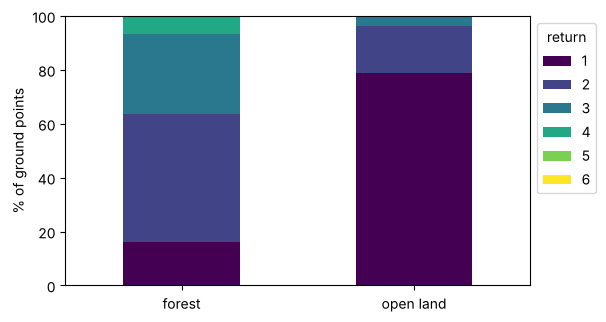

In [3]:
RES = 2.0                     # ◀ parameter: raster pixel size (m)
FOREST_H = 5                  # ◀ parameter: surface height above ground from which it counts as "forest" (m)
dtm, tf = cuzk_raster("dmr5g", X0, Y0, X1, Y1, RES)
dsm_l, _ = cuzk_raster("dmp1g", X0, Y0, X1, Y1, RES)
chm_l = dsm_l - dtm
r, c = rasterio.transform.rowcol(tf, np.asarray(ground.x), np.asarray(ground.y))
forest = chm_l[np.clip(r, 0, chm_l.shape[0] - 1), np.clip(c, 0, chm_l.shape[1] - 1)] > FOREST_H
rn = np.asarray(ground.return_number)
share = pd.DataFrame({"forest": pd.Series(rn[forest]).value_counts(normalize=True), "open land": pd.Series(rn[~forest]).value_counts(normalize=True)}).fillna(0) * 100
share.index.name = "return number"
print(f"ground points: in the forest {forest.sum()} ({forest.sum() / ((chm_l > FOREST_H).sum() * RES**2):.3f}/m²), in the open {(~forest).sum()} ({(~forest).sum() / ((chm_l <= FOREST_H).sum() * RES**2):.3f}/m²)")
print(share.round(1))
share.T.plot.bar(stacked=True, figsize=(6, 3.5), colormap="viridis", ylabel="% of ground points", rot=0); plt.legend(title="return", bbox_to_anchor=(1, 1)); plt.show()

> **✏️ Task 2.** What share of ground points in the forest comes from the 2nd or a later return, and what share in the open? Why is it not zero in the open? What would happen to the terrain model under the forest if the scanner recorded only the first return? And why does photogrammetry (SfM) not find the ground under a closed canopy at all?

*Your answer:* 

## 3. CHM from lidar and from photogrammetry

CHM = DSM − DTM. The DTM always comes from lidar (DMR 5G). The DSM comes once from lidar (DMP 1G) and once from image matching of aerial survey photographs (DMP OK), which ČÚZK took later (aerial survey photography usually takes place from spring to summer). Image matching is the same principle as drone photogrammetry.

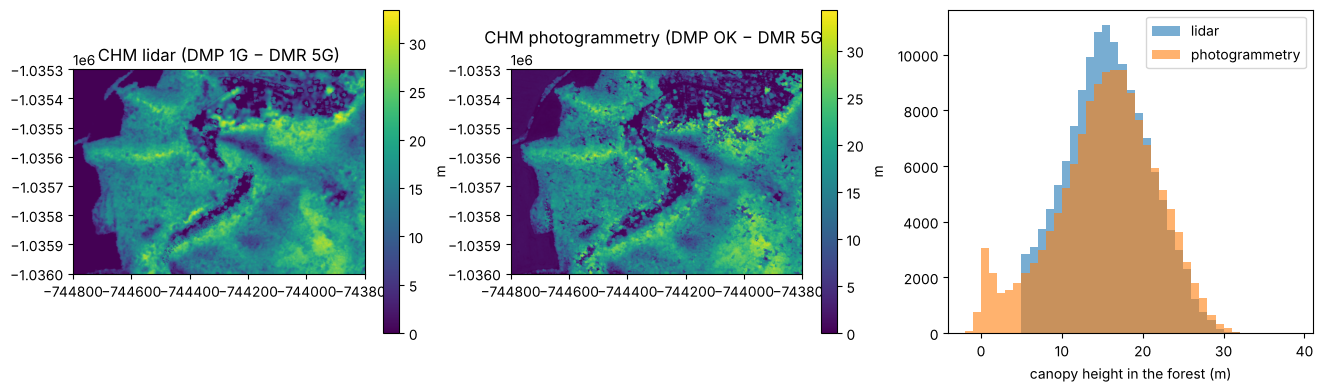

      lidar  photogrammetry
mean   15.8            15.3
50%    15.8            15.8
95%    24.4            25.0
max    33.4            34.4


In [4]:
dsm_p, _ = cuzk_raster("dmp_obrazova_korelace", X0, Y0, X1, Y1, RES)
chm_p = dsm_p - dtm
ext = (X0, X1, Y0, Y1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (name, v) in zip(ax, [("CHM lidar (DMP 1G − DMR 5G)", chm_l), ("CHM photogrammetry (DMP OK − DMR 5G)", chm_p)]):
    im = a.imshow(np.clip(v, 0, 35), extent=ext, cmap="viridis"); a.set_title(name); plt.colorbar(im, ax=a, label="m")
bins = np.arange(-2, 40, 1)
ax[2].hist(chm_l[chm_l > FOREST_H], bins, alpha=0.6, label="lidar"); ax[2].hist(chm_p[chm_l > FOREST_H], bins, alpha=0.6, label="photogrammetry")
ax[2].set_xlabel("canopy height in the forest (m)"); ax[2].legend(); plt.show()
fm = chm_l > FOREST_H
print(pd.DataFrame({"lidar": pd.Series(chm_l[fm]).describe(percentiles=[0.5, 0.95]), "photogrammetry": pd.Series(chm_p[fm]).describe(percentiles=[0.5, 0.95])}).loc[["mean", "50%", "95%", "max"]].round(1))

> **✏️ Task 3.** Which CHM shows taller vegetation in the forest, and by how much (median, 95th percentile)? Find at least three reasons: the years between acquisitions, leaves in summer and at the time of scanning, how image matching "smooths over" gaps between crowns. Where in the map are the differences largest?

*Your answer:* 

## 4. A profile through the forest

Points of both clouds in a strip along a chosen line, and profiles of the three surfaces.

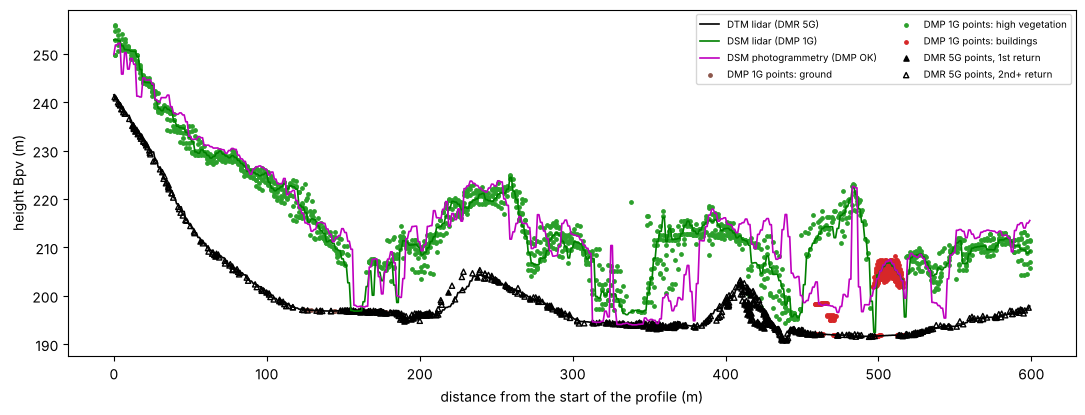

In [5]:
A_XY = (-744300, -1035950)    # ◀ parameter: start of the profile (S-JTSK, m)
B_XY = (-744300, -1035350)    # ◀ parameter: end of the profile
HALF_W = 5                    # ◀ parameter: half-width of the strip (m)
a, b = np.array(A_XY, float), np.array(B_XY, float); u = (b - a) / np.linalg.norm(b - a); n = np.array([-u[1], u[0]])
def strip(pts):
    d = np.c_[np.asarray(pts.x), np.asarray(pts.y)] - a
    s, o = d @ u, d @ n; m = (np.abs(o) <= HALF_W) & (s >= 0) & (s <= np.linalg.norm(b - a))
    return s[m], np.asarray(pts.z)[m], m
s_vals = np.arange(0, np.linalg.norm(b - a), RES / 2)
xy = a + np.outer(s_vals, u)
rr, cc = rasterio.transform.rowcol(tf, xy[:, 0], xy[:, 1])
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, v, st in [("DTM lidar (DMR 5G)", dtm, "k-"), ("DSM lidar (DMP 1G)", dsm_l, "g-"), ("DSM photogrammetry (DMP OK)", dsm_p, "m-")]:
    ax.plot(s_vals, v[rr, cc], st, lw=1.2, label=name)
s, z, m = strip(surface)
for cl, col in zip(CLS, ["tab:brown", "tab:green", "tab:red"]):
    k = np.asarray(surface.classification)[m] == cl; ax.scatter(s[k], z[k], s=6, c=col, label=f"DMP 1G points: {CLS[cl]}")
s, z, m = strip(ground); k = np.asarray(ground.return_number)[m] > 1
ax.scatter(s[~k], z[~k], s=14, marker="^", c="k", label="DMR 5G points, 1st return"); ax.scatter(s[k], z[k], s=14, marker="^", facecolors="none", edgecolors="k", label="DMR 5G points, 2nd+ return")
ax.set_xlabel("distance from the start of the profile (m)"); ax.set_ylabel("height Bpv (m)"); ax.legend(fontsize=7, ncol=2); plt.show()

> **✏️ Task 4.** Where in the profile is the forest and where the open land? How do the lidar and photogrammetric DSMs differ at the forest edge and in gaps between crowns? Which ground points in the forest come from the 2nd or a later return? Move the profile elsewhere (e.g. across the valley or buildings) and describe what you see.

*Your answer:* 

## 5. Tree tops

We look for a tree top as a local maximum of the CHM within a window of given size that is higher than a chosen limit. We use the photogrammetric DSM at its full resolution of 0.5 m.

window 5 m, limit 10 m: 785 tops on 9.0 ha = 87 trees/ha, median height 19.6 m


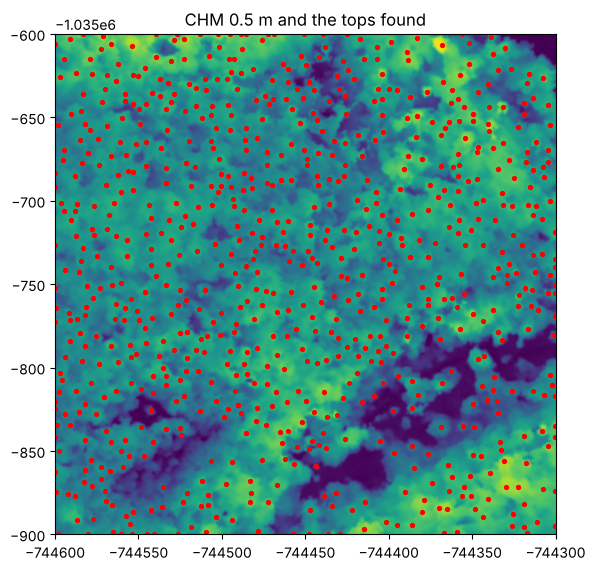

In [6]:
WIN = 5                       # ◀ parameter: window size for the local maximum (m)
MIN_H = 10                    # ◀ parameter: minimum tree height (m)
SUB = (-744600, -1035900, -744300, -1035600)   # ◀ parameter: a smaller window in the forest (S-JTSK, m)
d05, t05 = cuzk_raster("dmp_obrazova_korelace", *SUB, res=0.5)
g05, _ = cuzk_raster("dmr5g", *SUB, res=0.5)
chm05 = ndi.gaussian_filter(d05 - g05, 1)
k = max(3, int(round(WIN / 0.5)) | 1)
tops = (chm05 == ndi.maximum_filter(chm05, size=k)) & (chm05 > MIN_H)
rows_, cols_ = np.nonzero(tops)
ha = (SUB[2] - SUB[0]) * (SUB[3] - SUB[1]) / 1e4
print(f"window {WIN} m, limit {MIN_H} m: {tops.sum()} tops on {ha:.1f} ha = {tops.sum() / ha:.0f} trees/ha, median height {np.median(chm05[tops]):.1f} m")
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(np.clip(chm05, 0, 35), cmap="viridis", extent=(SUB[0], SUB[2], SUB[1], SUB[3]))
xs, ys = rasterio.transform.xy(t05, rows_, cols_)
ax.scatter(xs, ys, s=8, c="r"); ax.set_title("CHM 0.5 m and the tops found"); plt.show()

> **✏️ Task 5.** How many trees per hectare do you find with a window of 3 m, 5 m and 9 m? Which number is closest to reality if the crowns are about 8–12 m across, and why does a small window overestimate the count? What would happen to the count if you used the lidar CHM with a 2 m pixel?

*Your answer:* 

## 6. What changed between the acquisitions

The difference between the photogrammetric and the lidar CHM shows forest growth, felling and the errors of both methods. ČÚZK gives the accuracy as the total root mean square height error: DMR 5G 0.18 m in open and 0.3 m in forested terrain, DMP 1G 0.4 m for buildings and 0.7 m for vegetation.

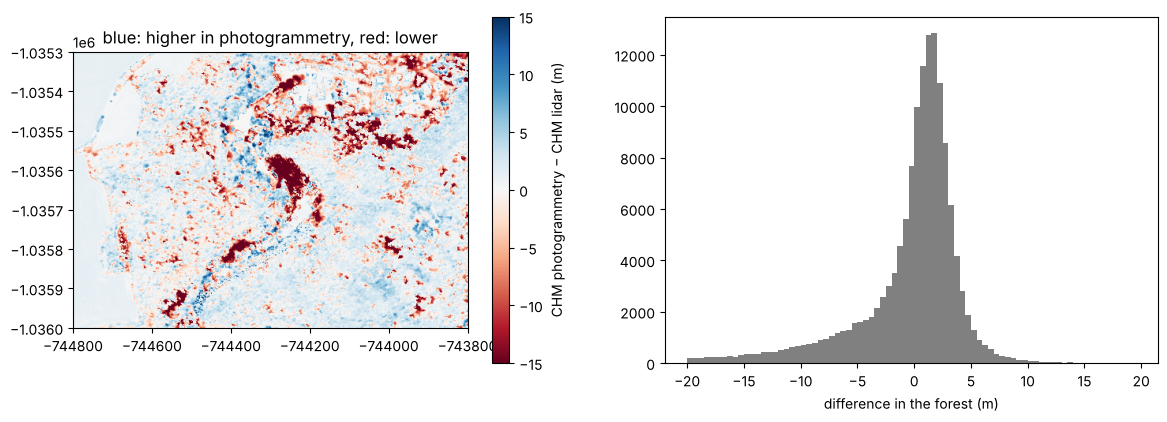

in the forest: median difference +0.8 m; more than 5 m higher on 4 %, more than 5 m lower on 13 % of the area


In [7]:
CHANGE = 5                    # ◀ parameter: height difference (m) from which we count it as a change
diff = chm_p - chm_l
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
im = ax[0].imshow(np.clip(diff, -15, 15), extent=ext, cmap="RdBu"); plt.colorbar(im, ax=ax[0], label="CHM photogrammetry − CHM lidar (m)")
ax[0].set_title("blue: higher in photogrammetry, red: lower")
ax[1].hist(diff[fm], np.arange(-20, 20, 0.5), color="gray"); ax[1].set_xlabel("difference in the forest (m)"); plt.show()
print(f"in the forest: median difference {np.median(diff[fm]):+.1f} m; more than {CHANGE} m higher on {100 * (diff[fm] > CHANGE).mean():.0f} %, more than {CHANGE} m lower on {100 * (diff[fm] < -CHANGE).mean():.0f} % of the area")

> **✏️ Task 6.** Is the median difference in the forest larger than the stated accuracy of both models explains? How much would the forest have had to grow over those years, and is that realistic (look up the typical annual height increment of a mature broadleaved forest)? Find places in the map where the forest disappeared (felling, windthrow) or appeared. Why can canopy height not be computed at all from a single photogrammetric DSM without a lidar DTM?

*Your answer:* 

---
### Data sources and references

- ČÚZK: Digital Terrain Model of the Czech Republic of the 5th generation (DMR 5G), total root mean square height error 0.18 m in open and 0.3 m in forested terrain; Digital Surface Model of the Czech Republic of the 1st generation (DMP 1G), 0.4 m for buildings and 0.7 m for vegetation; Digital Surface Model from image matching (DMP OK). https://geoportal.cuzk.gov.cz
- LAZ download: ČÚZK Atom service, https://atom.cuzk.cz/DMR5G-SJTSK/DMR5G-SJTSK.xml and https://atom.cuzk.cz/DMP1G-SJTSK/DMP1G-SJTSK.xml; rasters: https://ags.cuzk.cz/arcgis2/rest/services
- ASPRS (2019). *LAS Specification 1.4 – R15* (point classes, return numbers, GPS time).
- White, J. C., Wulder, M. A., Vastaranta, M. et al. (2013). The utility of image-based point clouds for forest inventory: A comparison with airborne laser scanning. *Forests* 4(3), 518–536.

### How to cite

OpenSkyLab (2026). Lidar and photogrammetry in a forest: ČÚZK point clouds and models [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/lidar_canopy_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*